## 1. ĐỌC DỮ LIỆU

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

print("ĐỌC DỮ LIỆU")
df = pd.read_excel(Path("..") / "data" / "processed" / "clean_data.xlsx")
features = ["Fragrance", "Flavor", "Aftertaste", "Acidity", "Body", "Moisture"]
group_var = "Origin"
X = df[features]
y = df[group_var]
print("Kích thước dữ liệu:", df.shape)


ĐỌC DỮ LIỆU


Kích thước dữ liệu: (720, 7)


## 2. HÀM VẼ ELIP TIN CẬY (CONFIDENCE ELLIPSE)

In [2]:
def confidence_ellipse(x, y, ax, n_std=2.4477, facecolor='none', **kwargs):
    """
    Tạo plot của covariance confidence ellipse của x và y.
    n_std = 2.4477 tương đương với khoảng tin cậy 95% trong phân phối Chi-square (2 bậc tự do).
    """
    if x.size != y.size:
        raise ValueError("x và y phải có cùng kích thước")

    cov = np.cov(x, y)
    pearson = cov[0, 1]/np.sqrt(cov[0, 0] * cov[1, 1])
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                      facecolor=facecolor, **kwargs)
    
    scale_x = np.sqrt(cov[0, 0]) * n_std
    mean_x = np.mean(x)
    
    scale_y = np.sqrt(cov[1, 1]) * n_std
    mean_y = np.mean(y)
    
    transf = transforms.Affine2D() \
        .rotate_deg(45) \
        .scale(scale_x, scale_y) \
        .translate(mean_x, mean_y)
    
    ellipse.set_transform(transf + ax.transData)
    return ax.add_patch(ellipse)


## 3. VẼ ELIP PHÂN TÁN THEO PCA

PHÂN TÍCH THÀNH PHẦN CHÍNH (PCA)


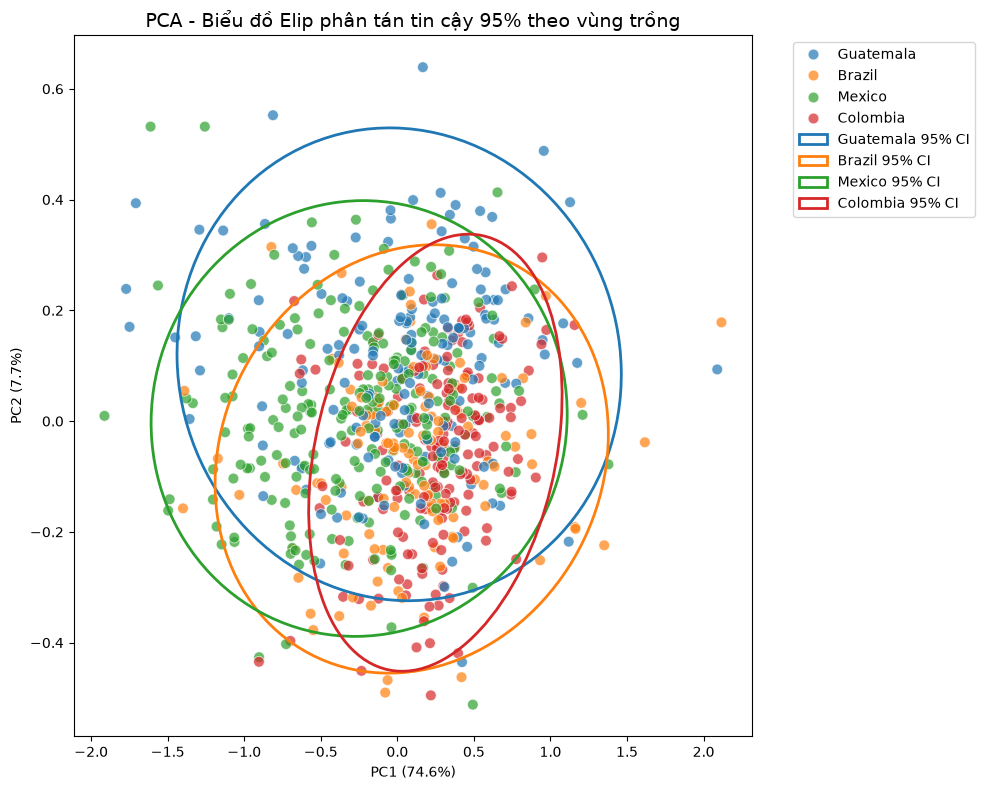

Đã lưu biểu đồ PCA tại: ..\figures\confidence_ellipses\confidence_ellipse_pca.png


In [3]:
print("PHÂN TÍCH THÀNH PHẦN CHÍNH (PCA)")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
df_pca['Origin'] = y.values

fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Origin', ax=ax, s=60, alpha=0.7)

for origin in df_pca['Origin'].unique():
    subset = df_pca[df_pca['Origin'] == origin]
    color = sns.color_palette()[df_pca['Origin'].unique().tolist().index(origin)]
    confidence_ellipse(subset['PC1'], subset['PC2'], ax, n_std=2.4477,
                       edgecolor=color, linewidth=2, label=f'{origin} 95% CI')
    
ax.set_title("PCA - Biểu đồ Elip phân tán tin cậy 95% theo vùng trồng", fontsize=14)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

file_path_pca = Path("..") / "figures" / "confidence_ellipses" / "confidence_ellipse_pca.png"
file_path_pca.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(file_path_pca, dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu biểu đồ PCA tại:", file_path_pca)


## 4. VẼ ELIP PHÂN TÁN THEO LDA

PHÂN TÍCH PHÂN BIỆT TUYẾN TÍNH (LDA)


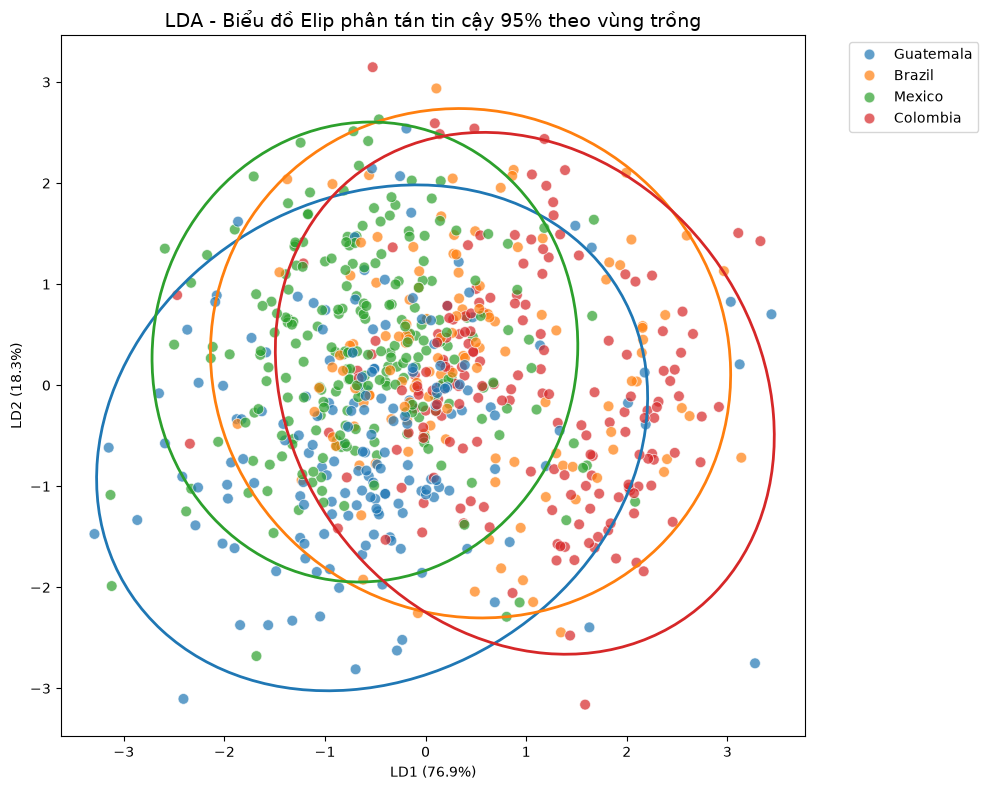

Đã lưu biểu đồ LDA tại: ..\figures\confidence_ellipses\confidence_ellipse_lda.png


In [4]:
print("PHÂN TÍCH PHÂN BIỆT TUYẾN TÍNH (LDA)")
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)
df_lda = pd.DataFrame(data=X_lda, columns=['LD1', 'LD2'])
df_lda['Origin'] = y.values

fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(data=df_lda, x='LD1', y='LD2', hue='Origin', ax=ax, s=60, alpha=0.7)

for origin in df_lda['Origin'].unique():
    subset = df_lda[df_lda['Origin'] == origin]
    color = sns.color_palette()[df_lda['Origin'].unique().tolist().index(origin)]
    confidence_ellipse(subset['LD1'], subset['LD2'], ax, n_std=2.4477,
                       edgecolor=color, linewidth=2)
    
ax.set_title("LDA - Biểu đồ Elip phân tán tin cậy 95% theo vùng trồng", fontsize=14)
ax.set_xlabel(f"LD1 ({lda.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"LD2 ({lda.explained_variance_ratio_[1]:.1%})")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

file_path_lda = Path("..") / "figures" / "confidence_ellipses" / "confidence_ellipse_lda.png"
file_path_lda.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(file_path_lda, dpi=300, bbox_inches='tight')
plt.show()
print("Đã lưu biểu đồ LDA tại:", file_path_lda)
